# Oral condition detector: YOLO (stage 2)

**IT2226 AI Innovator and Deep Learning Project: Dental Health Awareness and Affordability in Singapore**

This notebook trains **stage 2** of the two-stage pipeline described in the oral dataset's README. Stage 1 (`models/classifier/notebooks/Daniel/oral_condition_classifier.ipynb`) decides whether a mouth photo shows any of the five screened conditions. This notebook trains the YOLO detector that runs on the photos stage 1 flags: it draws a box around each finding and names it.

| id | condition |
|---|---|
| 0 | Calculus |
| 1 | Caries |
| 2 | Hypodontia |
| 3 | Mouth_Ulcer |
| 4 | Tooth_Discoloration |

It fine-tunes COCO-pretrained Ultralytics **YOLO11** models of three sizes under one training recipe. It also runs one ablation that leaves out the images Qwen labelled, picks one model by a rule fixed before training, and scores it on the held-out test set twice: once on all test images and once on only the images labelled entirely by people.

> **Scope.** This is a *screening and education aid*. It does not diagnose, and its output must always come with a recommendation to see a dentist. A box means "this area looks like it might be X". No box does not mean the mouth is healthy.

### Data issues and how this notebook handles them

| Issue | What this notebook does | Section |
|---|---|---|
| **Machine-drawn labels in train.** About 7,250 of the 25,850 training images were labelled at least partly by Qwen: kaggle_oral, mendeley and web images entirely; dentalai and zenodo have human caries boxes but Qwen boxes for the other conditions | The ablation `yolo11s_person` trains only on images labelled entirely by people. Test is always also scored on person-labelled images | 4, 6 |
| **Qwen-judged Normal images in val/test.** Qwen may have missed a small finding on some of the "healthy" images | Two test scores (`data.yaml` and `data_person.yaml`), plus a gallery of Normal test images where the model fires, to check by eye | 6.1, 6.3 |
| **mAP says little about false alarms on healthy mouths.** A detection on an empty image only counts as one false positive | Image-level scores: how many issue images get at least one box, how many Normal images get a false alarm, and per-condition recall and precision | 6.2 |
| **Class imbalance.** Caries is in about 10,700 training images, Hypodontia in about 2,500 | Per-class AP is always reported next to the mean | 2, 6 |
| **Very large photos.** dentalai and zenodo photos reach about 8,700 px. Decoding them every epoch (four per sample with mosaic) leaves the GPU waiting | One-time resized copy (at most 1,024 px, EXIF orientation applied) under `data/interim` | 3 |
| **Colour carries the finding.** Tooth discoloration and calculus are judged largely by colour | Hue augmentation almost off; saturation and brightness jitter reduced | 4 |
| **Source confound.** In val/test, every image with a condition is a 640×640 `roboflow_oral` export | Kept as a limitation: the test score measures roboflow-style photos. The per-source false-alarm table shows how the other sources behave | 6.2, 9 |
| **Duplicate photos** | The dataset already keeps every copy of a photo in the same split | n/a |

**Quick check.** Set `YOLO_QUICK=1` in the environment, or `QUICK = True` in the setup cell, to train each model for 2 epochs on 3% of train. The whole notebook then runs in about 15 minutes. Its outputs go to `quick/` subfolders, so they never overwrite real results.

## 0. Setup

In [1]:
# Install the notebook's dependencies into THIS kernel's Python environment.
# Safe to re-run: only missing packages are installed. Restart the kernel afterwards if anything was installed.
import importlib.util, subprocess, sys

PACKAGES = {  # import name -> pip package
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "PIL": "pillow", "cv2": "opencv-python",
    "yaml": "pyyaml", "tqdm": "tqdm", "IPython": "ipython", "ultralytics": "ultralytics>=8.3",  # 8.3+ has YOLO11
}
# PyTorch comes from its own index so the GPU build is installed (plain `pip install torch` gives the CPU build on Windows).
# It is installed BEFORE ultralytics, which would otherwise pull the CPU build in as a dependency.
# CUDA 12.8 wheels support RTX 50-series cards; use "https://download.pytorch.org/whl/cpu" on a machine without an NVIDIA GPU.
TORCH_INDEX = "https://download.pytorch.org/whl/cu128"


def pip_install(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])


installed = []
if importlib.util.find_spec("torch") is None or importlib.util.find_spec("torchvision") is None:
    print("installing torch + torchvision from", TORCH_INDEX)
    pip_install("torch", "torchvision", "--index-url", TORCH_INDEX); installed += ["torch", "torchvision"]
missing = [pkg for mod, pkg in PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("installing:", " ".join(missing))
    pip_install(*missing); installed += missing
print("installed:", " ".join(installed) if installed else "nothing, all packages present")
if installed:
    print(">>> Restart the kernel, then continue from the next cell.")

installed: nothing, all packages present


In [ ]:
import os, json, time, shutil, random, warnings, datetime
from contextlib import contextmanager
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
import yaml
from PIL import Image, ImageOps
import torch
import ultralytics
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_num_params, get_flops
from tqdm.auto import tqdm
from IPython.display import display, Markdown, Image as IPImage

warnings.filterwarnings("ignore", category=UserWarning)
Image.MAX_IMAGE_PIXELS = None
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})


def find_repo_root():
    # Look for shared/conditions.yaml, in order:
    #  1. upwards from $DLWIU_ROOT (manual override), the kernel's working directory and the notebook's own folder
    #     (VS Code exposes it as __vsc_ipynb_file__);
    #  2. the notebook's path re-rooted at this machine's home folder. On a remote Jupyter server VS Code sends the
    #     *client's* path (e.g. C:\Users\me\OneDrive\Documents\School\...), so we also try ~/Documents/School/...,
    #     ~/OneDrive/Documents/School/..., and every other tail of that path under the server's home;
    #  3. up to two levels below the kernel's working directory (e.g. C:\Jupyter\Deep-Learning-WIU).
    def search_up(start):
        for p in [start, *start.parents]:
            if (p / "shared" / "conditions.yaml").exists():
                return p.resolve()
        return None

    starts = []
    if os.environ.get("DLWIU_ROOT"):
        starts.append(Path(os.environ["DLWIU_ROOT"]))
    starts.append(Path.cwd())
    nb_dir = Path(globals()["__vsc_ipynb_file__"]).parent if "__vsc_ipynb_file__" in globals() else None
    if nb_dir is not None:
        starts.append(nb_dir)
    for s in starts:
        if (root := search_up(s)) is not None:
            return root
    if nb_dir is not None:
        parts = nb_dir.parts[1:]                       # drop the drive / anchor
        for base in [Path.home(), Path.home() / "OneDrive"]:
            for i in range(len(parts)):
                cand = base.joinpath(*parts[i:])
                if (root := search_up(cand)) is not None:      # cand need not exist (older clone)
                    return root
    for pattern in ["*/shared/conditions.yaml", "*/*/shared/conditions.yaml"]:
        hits = sorted(Path.cwd().glob(pattern))
        if hits:
            return hits[0].parents[1].resolve()
    raise FileNotFoundError(
        f"Could not find the Deep-Learning-WIU repo (looked upwards from {[str(s) for s in starts]}, under {Path.home()} and two levels "
        f"below {Path.cwd()}). If this kernel runs on a remote Jupyter server, the repo and data/raw/oral_dataset must "
        "exist on THAT machine. Clone it there, or point to it before this cell: "
        "os.environ['DLWIU_ROOT'] = r'C:\\path\\to\\Deep-Learning-WIU'")


# Quick check: 2 epochs on 3% of train per model, outputs under quick/ folders. Or set YOLO_QUICK=1 before starting Jupyter.
QUICK = os.environ.get("YOLO_QUICK", "0") == "1"

ROOT = find_repo_root()
RAW = ROOT / "data" / "raw"
SUB = "quick" if QUICK else ""
WEIGHTS = ROOT / "models" / "yolo_caries" / "weights" / "Daniel" / SUB   # final checkpoints (gitignored)
PRETRAINED = ROOT / "models" / "yolo_caries" / "weights" / "Daniel" / "pretrained"  # COCO-pretrained YOLO11 weights
RESULTS = ROOT / "models" / "yolo_caries" / "results" / "Daniel" / SUB   # metrics + figures for the report (committed)
FIGS = RESULTS / "figures"
HISTORY = RESULTS / "history"           # per-epoch training curves of every run (copied out of RUNS_DIR)
RUNS_DIR = RESULTS / "runs"             # Ultralytics run folders: plots, args, last/best.pt (gitignored by `runs/`)
EVAL_DIR = RUNS_DIR / "_eval"           # plots of every val/test evaluation
EXPERIMENT_LOG = ROOT / "models" / "yolo_caries" / "results" / "experiments.csv"   # the team's shared run log
for d in [WEIGHTS, PRETRAINED, RESULTS, FIGS, HISTORY, RUNS_DIR, EVAL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CFG = dict(
    seed=42,
    cache_max_side=1024,         # training copy keeps every image at <= 1,024 px (>= the largest imgsz you will try)
    imgsz=640,                   # roboflow_oral images, 85% of the data, are 640x640: training larger only upscales them
    # Runs trained in section 5 (registered in EXPERIMENTS, section 4). Trim this list for a shorter run.
    sweep=["yolo11s"],
    epochs=80, patience=15,      # stop when val fitness has not improved for 15 epochs
    # Images per step. yolo11m overrides it to 16 (EXPERIMENTS): at 32 it needs ~15.6 GB, and on Windows a card that runs
    # out of memory silently spills into system RAM and trains ~10x slower. Ultralytics accumulates gradients up to a
    # nominal batch of 64, so runs with different batch sizes still take comparable optimiser steps.
    batch=32,
    # Worker processes that decode and augment images. Lower it if the PC runs out of RAM.
    workers=8,
    tie_margin=0.005,            # runs within this val mAP50-95 of the best count as tied -> fewest GFLOPs wins
    pred_conf=0.05,              # lowest confidence kept when predicting for the image-level analysis (6.2)
    # A run that already has a checkpoint (weights/Daniel/<name>.pt) is never retrained; its saved results are reused.
    # A run interrupted mid-training resumes from its last.pt. List run names here to retrain them from scratch,
    # e.g. ["yolo11s"], or "all" to retrain everything.
    retrain=[],
    quick=QUICK, quick_epochs=2, quick_fraction=0.03,
)
if QUICK:
    CFG.update(epochs=CFG["quick_epochs"], patience=CFG["quick_epochs"])


def seed_everything(seed=CFG["seed"]):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def rel(p):
    # Repo-relative POSIX path for manifests and logs (absolute if outside the repo).
    try:
        return Path(p).resolve().relative_to(ROOT).as_posix()
    except ValueError:
        return str(p)


@contextmanager
def working_dir(path):
    # Ultralytics drops files in the current folder (yolo11n.pt for its AMP check), so it runs inside PRETRAINED.
    old = Path.cwd()
    os.chdir(path)
    try:
        yield
    finally:
        os.chdir(old)


def to_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))


seed_everything()
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("repo root:", ROOT, "| QUICK mode" if QUICK else "")
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| device:",
      torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU (training will be very slow)")

repo root: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU 
ultralytics 8.4.211 | torch 2.10.0+cu130 | device: NVIDIA GeForce RTX 5070 Ti


C:\Users\Dani\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the oral dataset

`labels.csv` has one row per image. YOLO uses only the rows with `in_yolo == 1`: the extra healthy training images exist for the classifier and never reach the detector (see the dataset README). Every YOLO label file is read once into a table with one row per box: `class cx cy w h`, normalised to 0-1. An empty label file means a Normal image.

In [3]:
def find_dataset():
    # Folder holding labels.csv + data.yaml of the unzipped oral dataset; $ORAL_DATASET_DIR overrides the search.
    if os.environ.get("ORAL_DATASET_DIR"):
        cands = [Path(os.environ["ORAL_DATASET_DIR"]) / "labels.csv"]
    else:
        cands = sorted(RAW.glob("oral_dataset/**/labels.csv"), key=lambda p: len(p.parts))
    cands = [p for p in cands if p.exists() and (p.parent / "data.yaml").exists()]
    if not cands:
        zips = sorted(RAW.glob("oral_dataset/*.zip"))
        hint = f" Found {zips[0].name}: unzip it inside {zips[0].parent}." if zips else ""
        raise FileNotFoundError(f"No oral dataset (labels.csv + data.yaml) under {RAW / 'oral_dataset'}.{hint}")
    return cands[0].parent


DATA_DIR = find_dataset()
CONDITIONS = yaml.safe_load(open(DATA_DIR / "data.yaml"))["names"]
NC = len(CONDITIONS)
SPLITS = ["train", "val", "test"]

full = pd.read_csv(DATA_DIR / "labels.csv")
df = full[full.in_yolo == 1].reset_index(drop=True)
df["person"] = df.label_by.eq("person")          # labelled entirely by people


def read_list(name):
    # Image list files hold "./images/..." paths relative to the dataset folder.
    return [ln.strip().removeprefix("./") for ln in (DATA_DIR / name).read_text().splitlines() if ln.strip()]


assert set(read_list("yolo_train.txt")) == set(df.image[df.split == "train"]), "yolo_train.txt != in_yolo train rows"
assert set(read_list("val_person.txt")) == set(df.image[(df.split == "val") & df.person])
assert set(read_list("test_person.txt")) == set(df.image[(df.split == "test") & df.person])


def label_file(img_rel, root=DATA_DIR):
    return root / Path("labels", *Path(img_rel).parts[1:]).with_suffix(".txt")


def read_boxes(img_rel):
    lines = [ln.split() for ln in label_file(img_rel).read_text().splitlines() if ln.strip()]
    assert all(len(ln) == 5 for ln in lines), f"{img_rel}: expected 'class cx cy w h' rows"
    return img_rel, np.array(lines, dtype=float).reshape(-1, 5)


with ThreadPoolExecutor(16) as ex:
    parsed = list(tqdm(ex.map(read_boxes, df.image), total=len(df), desc="reading labels"))
boxes = pd.DataFrame(np.concatenate([r for _, r in parsed]), columns=["cls", "cx", "cy", "w", "h"])
boxes.insert(0, "image", np.repeat([i for i, _ in parsed], [len(r) for _, r in parsed]))
boxes["cls"] = boxes.cls.astype(int)
boxes = boxes.merge(df[["image", "split", "dataset", "label_by", "boxes_by", "person"]], on="image")
boxes["condition"] = np.array(CONDITIONS)[boxes.cls]
GT = {img: g[["cls", "cx", "cy", "w", "h"]].to_numpy() for img, g in boxes.groupby("image")}

# Image-level ground truth from the boxes: one bool column per condition.
GT_IMG = (pd.crosstab(boxes.image, boxes.condition) > 0).reindex(index=df.image, columns=CONDITIONS, fill_value=False)
GT_IMG["any"] = GT_IMG.any(axis=1)

# Sanity checks
assert boxes.cls.between(0, NC - 1).all(), "class id out of range"
assert (boxes.w > 0).all() and (boxes.h > 0).all(), "empty box"
edges = pd.concat([boxes.cx - boxes.w / 2, boxes.cx + boxes.w / 2, boxes.cy - boxes.h / 2, boxes.cy + boxes.h / 2], axis=1)
print(f"boxes reaching past the image edge by > 1%: {int(((edges < -0.01) | (edges > 1.01)).any(axis=1).sum())}")
mismatch = (GT_IMG["any"].astype(int).values != df.has_issue.values).sum()
print(f"images whose label file disagrees with has_issue: {mismatch}")
csv_cls = df.set_index("image")[CONDITIONS].astype(bool)
print(f"images whose boxes name other conditions than labels.csv: {int((csv_cls != GT_IMG[CONDITIONS]).any(axis=1).sum())}")

print(f"\ndataset: {DATA_DIR}\n{len(df)} YOLO images, {len(boxes)} boxes | classes: {CONDITIONS}")
pd.crosstab(df.split, df.has_issue.map({0: "normal (no boxes)", 1: "with boxes"}), margins=True).loc[SPLITS + ["All"]]

reading labels: 100%|██████████| 31909/31909 [00:12<00:00, 2622.12it/s]


boxes reaching past the image edge by > 1%: 0
images whose label file disagrees with has_issue: 0
images whose boxes name other conditions than labels.csv: 0

dataset: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\raw\oral_dataset\oral_dataset
31909 YOLO images, 134989 boxes | classes: ['Calculus', 'Caries', 'Hypodontia', 'Mouth_Ulcer', 'Tooth_Discoloration']


has_issue,normal (no boxes),with boxes,All
split,,,
train,2603,23429,26032
val,609,2332,2941
test,621,2315,2936
All,3833,28076,31909


## 2. Exploratory analysis

What the detector has to learn: how many examples of each condition there are, how many boxes an image holds, how big the boxes are, and who drew them.

images            boxes             boxes/image (train)
                     train  val test  train   val  test                    
condition                                                                  
Calculus              3661  369  401  14264  1526  1465                 3.9
Caries               10738  830  837  36006  2384  2447                 3.4
Hypodontia            2628  311  335   4874   607   665                 1.9
Mouth_Ulcer           4699  574  543   9482  1119  1133                 2.0
Tooth_Discoloration   7832  937  898  47649  5462  5906                 6.1
Normal (no boxes)     2603  609  621      0     0     0                 0.0

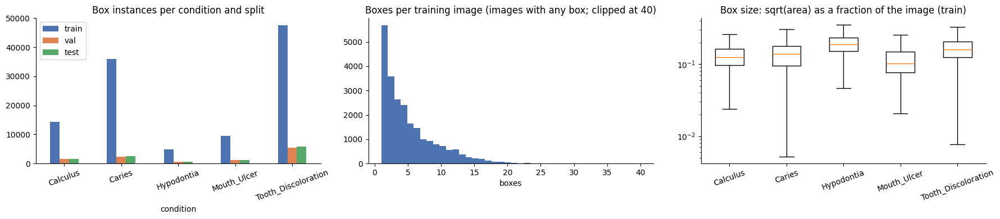

In [4]:
CLASS_COLORS = ["#E69F00", "#D55E00", "#0072B2", "#CC79A7", "#009E73"]   # Okabe-Ito, colour-blind safe
SHORT = dict(zip(CONDITIONS, ["Calculus", "Caries", "Hypodont.", "Ulcer", "Discolor."]))   # labels on drawn boxes

img_cls = boxes.drop_duplicates(["image", "cls"])
summary = pd.concat({
    "images": pd.crosstab(img_cls.condition, img_cls.split),
    "boxes": pd.crosstab(boxes.condition, boxes.split),
}, axis=1).reindex(CONDITIONS)
summary = summary.reindex(columns=pd.MultiIndex.from_product([["images", "boxes"], SPLITS]))
summary.loc["Normal (no boxes)"] = [*(~GT_IMG["any"]).groupby(df.set_index("image").split).sum().reindex(SPLITS), 0, 0, 0]
summary["boxes/image (train)"] = (summary[("boxes", "train")] / summary[("images", "train")]).round(1)
display(summary)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
summary.loc[CONDITIONS, "boxes"].plot.bar(ax=ax[0], rot=20, color=["#4C72B0", "#DD8452", "#55A868"])
ax[0].set_title("Box instances per condition and split")
per_img = boxes[boxes.split == "train"].groupby("image").size()
ax[1].hist(per_img.clip(upper=40), bins=40, color="#4C72B0")
ax[1].set_title("Boxes per training image (images with any box; clipped at 40)"); ax[1].set_xlabel("boxes")
tr = boxes[boxes.split == "train"]
ax[2].boxplot([np.sqrt(tr.w * tr.h)[tr.cls == c] for c in range(NC)], showfliers=False)
ax[2].set_xticks(range(1, NC + 1), CONDITIONS, rotation=20); ax[2].set_yscale("log")
ax[2].set_title("Box size: sqrt(area) as a fraction of the image (train)")
plt.tight_layout(); plt.savefig(FIGS / "eda_classes_and_boxes.png", bbox_inches="tight"); plt.show()

In [5]:
# Who drew the boxes: "human" = people (roboflow_oral), "model" = Qwen, and dentalai/zenodo mix human caries boxes
# with Qwen boxes for the other conditions.
print("Training boxes per condition, by who drew them:")
display(pd.crosstab(tr.condition, tr.boxes_by, margins=True))
print("Median box size, sqrt(area) as a fraction of the image, by who drew it (train):")
display(tr.assign(side=np.sqrt(tr.w * tr.h)).pivot_table(index="condition", columns="boxes_by", values="side",
                                                         aggfunc="median").round(3))
print("Training images labelled entirely by people vs. with Qwen involved:")
display(pd.crosstab(df[df.split == "train"].dataset, df[df.split == "train"].label_by, margins=True))

Training boxes per condition, by who drew them:


boxes_by,human,human (caries) + model (other classes),"human (caries) + model (other classes) + model (hypodontia gap, checked by a second request)",model,"model + model (hypodontia gap, checked by a second request)",All
condition,,,,,,
Calculus,13709,184,0,370,1,14264
Caries,22682,11951,74,1296,3,36006
Hypodontia,4736,0,39,48,51,4874
Mouth_Ulcer,8790,19,1,672,0,9482
Tooth_Discoloration,45367,729,1,1535,17,47649
All,95284,12883,115,3921,72,112275


Median box size, sqrt(area) as a fraction of the image, by who drew it (train):


boxes_by,human,human (caries) + model (other classes),"human (caries) + model (other classes) + model (hypodontia gap, checked by a second request)",model,"model + model (hypodontia gap, checked by a second request)"
condition,,,,,
Calculus,0.126,0.071,NaN,0.105,0.173
Caries,0.138,0.152,0.047,0.082,0.097
Hypodontia,0.190,NaN,0.139,0.173,0.145
Mouth_Ulcer,0.105,0.058,0.083,0.082,NaN
Tooth_Discoloration,0.162,0.130,0.259,0.169,0.055


Training images labelled entirely by people vs. with Qwen involved:


label_by,person,person (caries) + qwen (other conditions),person (condition) + qwen (boxes),qwen,All
dataset,,,,,
dentalai,0,1927,0,0,1927
external_clean,0,0,0,369,369
kaggle_oral,34,0,725,29,788
mendeley_noncaries,0,0,0,2118,2118
roboflow_oral,18630,0,0,0,18630
zenodo,0,2200,0,0,2200
All,18664,4127,725,2516,26032


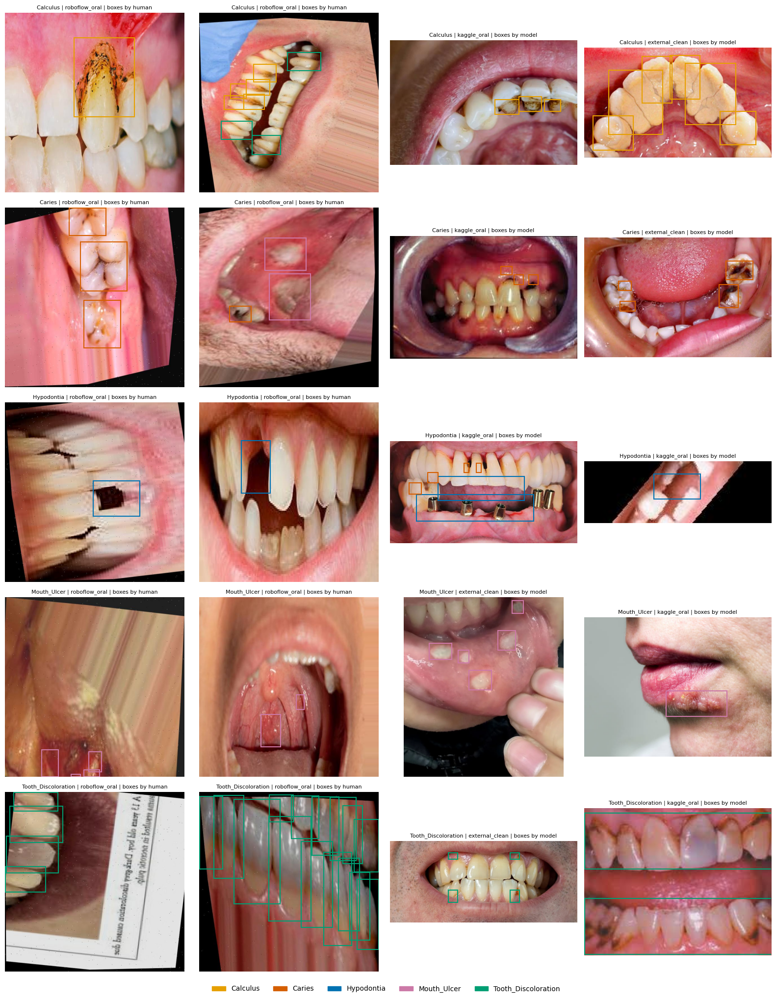

In [6]:
def load_rgb(src, max_side=None):
    # Open, honour EXIF orientation (the frame the labels were drawn in), convert to RGB and optionally downsize.
    im = Image.open(src)
    if max_side and im.format == "JPEG":
        im.draft("RGB", (max_side, max_side))   # fast reduced-size JPEG decode
    im = ImageOps.exif_transpose(im).convert("RGB")
    if max_side:
        im.thumbnail((max_side, max_side), Image.LANCZOS)
    return im


def draw(ax, img_rel, root=None, gt=True, preds=None, conf=0.25, title=None):
    # GT boxes: dashed when predictions are shown too, solid otherwise. Predictions: solid, labelled with confidence.
    im = load_rgb((root or DATA_DIR) / img_rel, max_side=800)
    W, H = im.size
    ax.imshow(im); ax.set_axis_off()
    if gt:
        for c, cx, cy, w, h in GT.get(img_rel, []):
            ax.add_patch(Rectangle(((cx - w / 2) * W, (cy - h / 2) * H), w * W, h * H, fill=False,
                                   ec=CLASS_COLORS[int(c)], lw=1.5, ls="--" if preds is not None else "-"))
    if preds is not None:
        for p in preds[preds.conf >= conf].itertuples():
            ax.add_patch(Rectangle((p.x1 * W, p.y1 * H), (p.x2 - p.x1) * W, (p.y2 - p.y1) * H, fill=False,
                                   ec=CLASS_COLORS[p.cls], lw=2))
            ax.text(p.x1 * W, p.y1 * H, f"{SHORT[CONDITIONS[p.cls]]} {p.conf:.2f}", fontsize=6, color="white",
                    va="bottom", bbox=dict(fc=CLASS_COLORS[p.cls], lw=0, pad=1))
    if title:
        ax.set_title(title, fontsize=8)


def class_legend(fig, extra=()):
    fig.legend(handles=[Patch(color=c, label=n) for c, n in zip(CLASS_COLORS, CONDITIONS)] + list(extra),
               loc="lower center", ncol=NC + len(extra), frameon=False, bbox_to_anchor=(0.5, -0.02))


# Four training examples per condition: two with boxes drawn by people, two by Qwen where available.
rng = np.random.default_rng(CFG["seed"])
fig, axes = plt.subplots(NC, 4, figsize=(16, 4 * NC))
for c, row in enumerate(axes):
    pool = tr[tr.cls == c].drop_duplicates("image")
    picks = []
    for by in ["human", "model"]:
        imgs = pool[pool.boxes_by == by].image.to_numpy()
        picks += list(rng.choice(imgs, min(2, len(imgs)), replace=False))
    others = pool.image[~pool.image.isin(picks)].to_numpy()
    picks += list(rng.choice(others, 4 - len(picks), replace=False))
    for ax, img in zip(row, picks):
        info = df.set_index("image").loc[img]
        draw(ax, img, title=f"{CONDITIONS[c]} | {info.dataset} | boxes by {info.boxes_by}")
class_legend(fig)
plt.tight_layout(); plt.savefig(FIGS / "eda_examples.png", bbox_inches="tight", dpi=80); plt.show()

**Reading the tables and plots.** Check these points against the output above:
- **Imbalance.** Caries and Tooth_Discoloration have several times more boxes than Hypodontia. Expect lower AP on the rare classes, and judge the model per class, not only by the mean.
- **Many small boxes.** Caries and calculus images often hold many small boxes (individual teeth or lesions). Hypodontia and ulcers are fewer, larger regions. Small objects are where a larger model or a larger `imgsz` usually helps.
- **Who drew the boxes.** If Qwen's boxes are much larger than people's for the same condition, the detector is learning two box styles. The `yolo11s_person` ablation in section 5 measures whether those images help or hurt.

## 3. Training copy of the images

Ultralytics decodes every image from disk every epoch, and with mosaic augmentation it decodes four images per training sample. A 5,000 px dentalai photo then costs far more than the 640 px roboflow exports. This step writes a copy of the YOLO images once, to `data/interim/Daniel/yolo_oral_1024/`:
- images larger than `cache_max_side`, or with an EXIF rotation, are rotated upright (the frame the labels were drawn in), downsized and re-saved. Box coordinates are fractions of the image, so the label files stay valid;
- every other image is **hard-linked** (no extra disk space), or copied if hard links are not possible;
- label files, image lists and both `data*.yaml` files are copied unchanged. One extra list, `yolo_train_person.txt`, holds the training images labelled entirely by people, for the ablation.

Re-running only processes what is missing. Files that are no longer in the dataset are removed, because Ultralytics reads `images/val` and `images/test` as whole folders.

training copy: 100%|██████████| 31909/31909 [00:01<00:00, 27063.79it/s]


training copy: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\interim\Daniel\yolo_oral_1024  (9 s, 0 stale files removed)
kept    31909
per split: {'train': 26032, 'val': 2941, 'test': 2936} | person-only train images: 18664


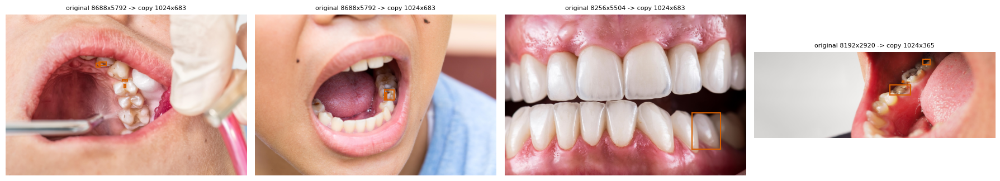

In [7]:
TRAIN_DATA = ROOT / "data" / "interim" / "Daniel" / f"yolo_oral_{CFG['cache_max_side']}"


def copy_image(img_rel, max_side=CFG["cache_max_side"]):
    src, dst = DATA_DIR / img_rel, TRAIN_DATA / img_rel
    if dst.exists():
        return "kept"
    with Image.open(src) as im:
        w, h = im.size
        rotated = im.getexif().get(0x0112, 1) != 1
    if max(w, h) <= max_side and not rotated:
        try:
            os.link(src, dst); return "linked"
        except OSError:
            shutil.copy2(src, dst); return "copied"
    im = load_rgb(src, max_side)
    tmp = dst.with_name(dst.stem + ".part" + dst.suffix)   # an interrupted save never leaves a half-written image
    im.save(tmp, **({"quality": 95} if dst.suffix.lower() in (".jpg", ".jpeg") else {}))
    tmp.replace(dst)
    return "resized"


def build_training_copy():
    for kind in ["images", "labels"]:
        for s in SPLITS:
            (TRAIN_DATA / kind / s).mkdir(parents=True, exist_ok=True)
    want = set(df.image)
    want_stems = {Path(i).with_suffix("").as_posix() for i in want}
    stale = [p for s in SPLITS for p in (TRAIN_DATA / "images" / s).iterdir()
             if f"images/{s}/{p.name}" not in want]
    stale += [p for s in SPLITS for p in (TRAIN_DATA / "labels" / s).glob("*.txt")
              if f"images/{s}/{p.stem}" not in want_stems]
    for p in stale:
        p.unlink()
    with ThreadPoolExecutor(12) as ex:
        status = pd.Series(list(tqdm(ex.map(copy_image, df.image), total=len(df), desc="training copy")))
    for img in df.image:                               # labels are tiny: copy when missing or changed
        src, dst = label_file(img), label_file(img, TRAIN_DATA)
        if not dst.exists() or dst.stat().st_size != src.stat().st_size or dst.stat().st_mtime < src.stat().st_mtime:
            shutil.copy2(src, dst)
    for name in ["yolo_train.txt", "val_person.txt", "test_person.txt", "data.yaml", "data_person.yaml", "classes.txt"]:
        shutil.copy2(DATA_DIR / name, TRAIN_DATA / name)
    person_train = df.image[(df.split == "train") & df.person]
    (TRAIN_DATA / "yolo_train_person.txt").write_text("".join(f"./{p}\n" for p in person_train))
    (TRAIN_DATA / "data_train_person.yaml").write_text(
        "# Ablation: train only on images labelled entirely by people. val / test are the same as data.yaml.\n"
        + yaml.safe_dump(dict(train="yolo_train_person.txt", val="images/val", test="images/test", nc=NC,
                              names=CONDITIONS), sort_keys=False, default_flow_style=None))
    return status.value_counts(), len(stale)


t0 = time.time()
counts, n_stale = build_training_copy()
print(f"training copy: {TRAIN_DATA}  ({time.time() - t0:.0f} s, {n_stale} stale files removed)")
print(counts.to_string())
for s in SPLITS:
    n = sum(1 for _ in (TRAIN_DATA / "images" / s).iterdir())
    assert n == (df.split == s).sum(), f"{s}: {n} images in the copy, expected {(df.split == s).sum()}"
print("per split:", {s: int((df.split == s).sum()) for s in SPLITS},
      f"| person-only train images: {int(((df.split == 'train') & df.person).sum())}")

# Check that boxes still line up on the resized copies: the four largest originals, drawn from the copy.
idx_csv = ROOT / "data" / "processed" / "classifier" / "Daniel" / "oral_dataset_index.csv"   # sizes, if stage 1 ran
big = df[df.has_issue == 1]
if idx_csv.exists():
    sizes = pd.read_csv(idx_csv, usecols=["md5", "orig_w", "orig_h"]).set_index("md5")
    big = big.assign(side=big.md5.map(sizes[["orig_w", "orig_h"]].max(axis=1))).sort_values("side", ascending=False)
else:
    big = big[big.dataset.isin(["dentalai", "zenodo"])]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, img in zip(axes, big.image.head(4)):
    with Image.open(DATA_DIR / img) as a, Image.open(TRAIN_DATA / img) as b:
        draw(ax, img, root=TRAIN_DATA, title=f"original {a.size[0]}x{a.size[1]} -> copy {b.size[0]}x{b.size[1]}")
plt.tight_layout(); plt.show()

## 4. Training setup

**Models.** Ultralytics YOLO11 detectors, pretrained on COCO, in three sizes: nano, small and medium. Every run uses the same recipe, so differences come from model size, or (for the ablation) from the training images.

| run | model | trained on | question it answers |
|---|---|---|---|
| `yolo11n` | YOLO11-nano, 2.6 M params | all of `yolo_train.txt` | how good is the smallest, fastest model? |
| `yolo11s` | YOLO11-small, 9.4 M | all | |
| `yolo11m` | YOLO11-medium, 20 M | all | does a bigger model pay off? |
| `yolo11s_person` | YOLO11-small | only images labelled entirely by people | do Qwen's labels help or hurt? (compare with `yolo11s`) |

**Recipe** (`TRAIN_ARGS` below): 640 px, batch 32 (16 for `yolo11m`, to fit in 16 GB), up to 80 epochs with early stopping (patience 15) on val fitness (0.1 × mAP50 + 0.9 × mAP50-95). The optimiser and learning rate are Ultralytics' `auto` choice (SGD, lr 0.01 for a run this long). Augmentation is Ultralytics' default (mosaic, random scale and translate, left-right flip) with three changes for mouth photos:
- **hue jitter almost off** (`hsv_h` 0.015 → 0.005), **saturation and brightness jitter reduced**: discoloration and calculus are colour findings, and a hue shift can turn a yellow-brown stain into a healthy shade;
- **no vertical flip**: an upside-down mouth is not a photo the app will see;
- **no rotation**: phone photos of a mouth are close to level.

**Selection rule, fixed before training.** The run with the highest **val mAP50-95** on `data.yaml` wins. Runs within 0.005 of the best count as tied; among tied runs the one with the fewest GFLOPs wins, because the model has to run behind a web app. Test images are used only after this choice.

In [8]:
EXPERIMENTS = {  # name -> pretrained weights + dataset yaml (inside TRAIN_DATA) + optional per-run overrides
    "yolo11n": dict(model="yolo11n.pt", data="data.yaml"),
    "yolo11s": dict(model="yolo11s.pt", data="data.yaml"),
    "yolo11m": dict(model="yolo11m.pt", data="data.yaml", args=dict(batch=16)),  # batch 32 overflows 16 GB
    "yolo11l": dict(model="yolo11l.pt", data="data.yaml", args=dict(batch=8)),   # not in the default sweep
    "yolo11s_person": dict(model="yolo11s.pt", data="data_train_person.yaml"),
}

TRAIN_ARGS = dict(
    imgsz=CFG["imgsz"], epochs=CFG["epochs"], patience=CFG["patience"], batch=CFG["batch"], workers=CFG["workers"],
    device=DEVICE, seed=CFG["seed"], deterministic=True, optimizer="auto", amp=True, cache=False,
    # augmentation (Ultralytics defaults except where commented)
    hsv_h=0.005,      # default 0.015: colour is part of the finding
    hsv_s=0.5,        # default 0.7
    hsv_v=0.3,        # default 0.4
    degrees=0.0, translate=0.1, scale=0.5, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.5, mosaic=1.0, mixup=0.0, close_mosaic=10,
    plots=True, val=True,
)
if QUICK:
    TRAIN_ARGS["fraction"] = CFG["quick_fraction"]
EVAL_DATA = TRAIN_DATA / "data.yaml"            # every run is compared on the same val set
EVAL_PERSON = TRAIN_DATA / "data_person.yaml"   # val / test images labelled entirely by people


def run_dir(name):
    return RUNS_DIR / name


def final_ckpt(name):
    return WEIGHTS / f"{name}.pt"


def finished(ckpt):
    # Ultralytics sets epoch = -1 when it strips a checkpoint at the end of training.
    return torch.load(ckpt, map_location="cpu", weights_only=False).get("epoch", -1) == -1


def wants_retrain(name):
    return CFG["retrain"] == "all" or name in CFG["retrain"]


def train_experiment(name):
    exp, rd = EXPERIMENTS[name], run_dir(name)
    last, best = rd / "weights" / "last.pt", rd / "weights" / "best.pt"
    if final_ckpt(name).exists() and not wants_retrain(name):
        print(f"[{name}] checkpoint exists ({rel(final_ckpt(name))}), reusing it")
        return
    if wants_retrain(name):
        shutil.rmtree(rd, ignore_errors=True); final_ckpt(name).unlink(missing_ok=True)
    seed_everything()
    t0 = time.time()
    with working_dir(PRETRAINED):
        if last.exists() and not finished(last):
            print(f"[{name}] resuming from {rel(last)}")
            YOLO(str(last)).train(resume=True)
        elif not best.exists():
            print(f"[{name}] training {exp['model']} on {exp['data']}")
            YOLO(str(PRETRAINED / exp["model"])).train(
                data=str(TRAIN_DATA / exp["data"]), project=str(RUNS_DIR), name=name, exist_ok=True,
                **{**TRAIN_ARGS, **exp.get("args", {})})
    shutil.copy2(best, final_ckpt(name))
    shutil.copy2(rd / "results.csv", HISTORY / f"{name}.csv")
    print(f"[{name}] done in {(time.time() - t0) / 60:.1f} min -> {rel(final_ckpt(name))}")


def evaluate(name, data_yaml, split, tag, plots=False):
    # Box-level metrics of a run's best checkpoint. Saved per run and reused unless the checkpoint is newer.
    out = run_dir(name) / f"eval_{tag}.json"
    if out.exists() and out.stat().st_mtime > final_ckpt(name).stat().st_mtime:
        return json.loads(out.read_text())
    with working_dir(PRETRAINED):
        model = YOLO(str(final_ckpt(name)))
        params, gflops = get_num_params(model.model), get_flops(model.model, CFG["imgsz"])
        m = model.val(data=str(data_yaml), split=split, imgsz=CFG["imgsz"], batch=CFG["batch"], workers=CFG["workers"],
                      device=DEVICE, conf=0.001, iou=0.7, plots=plots, project=str(EVAL_DIR), name=f"{name}_{tag}",
                      exist_ok=True, verbose=False)
    b = m.box
    f1 = b.f1_curve.mean(0)
    res = dict(run=name, data=Path(data_yaml).name, split=split, precision=b.mp, recall=b.mr, mAP50=b.map50,
               mAP50_95=b.map, f1_conf=float(b.px[int(np.argmax(f1))]), f1_max=float(f1.max()),
               inference_ms=m.speed["inference"], params_M=params / 1e6, GFLOPs=gflops, save_dir=str(m.save_dir),
               per_class={CONDITIONS[c]: dict(zip(["P", "R", "AP50", "AP50_95"], map(float, b.class_result(i))))
                          for i, c in enumerate(b.ap_class_index)})
    to_json(res, out)
    return res


def history(name):
    h = pd.read_csv(run_dir(name) / "results.csv")
    h.columns = h.columns.str.strip()
    return h


def train_list_size(name):
    t = yaml.safe_load(open(TRAIN_DATA / EXPERIMENTS[name]["data"]))["train"]
    n = sum(1 for ln in open(TRAIN_DATA / t) if ln.strip())
    return int(n * CFG["quick_fraction"]) if QUICK else n


unknown = [n for n in CFG["sweep"] if n not in EXPERIMENTS]
assert not unknown, f"not in EXPERIMENTS: {unknown}"
print("sweep:", CFG["sweep"])
print({k: v for k, v in TRAIN_ARGS.items() if k not in ("device", "plots", "val", "verbose")})

sweep: ['yolo11s']
{'imgsz': 640, 'epochs': 80, 'patience': 15, 'batch': 32, 'workers': 8, 'seed': 42, 'deterministic': True, 'optimizer': 'auto', 'amp': True, 'cache': False, 'hsv_h': 0.005, 'hsv_s': 0.5, 'hsv_v': 0.3, 'degrees': 0.0, 'translate': 0.1, 'scale': 0.5, 'shear': 0.0, 'perspective': 0.0, 'flipud': 0.0, 'fliplr': 0.5, 'mosaic': 1.0, 'mixup': 0.0, 'close_mosaic': 10}


## 5. Train the experiments

Each run writes its curves, plots and `last.pt`/`best.pt` to `results/Daniel/runs/<name>/`, then copies `best.pt` to `weights/Daniel/<name>.pt`. A run that already has that checkpoint is skipped. A run that was interrupted (kernel restart, crash, PC asleep) resumes from `last.pt` when this cell is re-run.

**Time.** Measured on an RTX 5070 Ti at 640 px: `yolo11s` trains at about 5.7 batches of 32 per second, so one epoch over the 25,850 training images, plus validation, takes about 3 minutes. `yolo11n` is about the same (image loading, not the GPU, limits it), and `yolo11m` takes roughly twice as long. With 80 epochs at most and early stopping, the whole sweep is about a day of training. Trim `CFG["sweep"]` for a shorter run, or run it overnight across several sessions: an interrupted run resumes.

In [ ]:
for name in CFG["sweep"]:
    train_experiment(name)

[yolo11s] training yolo11s.pt on data.yaml
New https://pypi.org/project/ultralytics/8.4.212 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.211  Python-3.13.14 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\interim\Daniel\yolo_oral_1024\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.005, hsv_s=0.5, hsv_v=0.3, imgsz=6

### 5.1 Comparison on validation

Every run's best checkpoint is re-scored on the same val set (`data.yaml`, all 2,941 val images) with Ultralytics' standard settings (conf 0.001, NMS IoU 0.7). The person-only val score (`data_person.yaml`) is shown alongside it, but the selection uses the first.

Ultralytics 8.4.211  Python-3.13.14 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 206.0±64.4 MB/s, size: 34.1 KB)
val: Scanning C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\interim\Daniel\yolo_oral_1024\labels\val.cache... 2941 images, 640 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2941/2941 1.2Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 92/92 3.3it/s 28.2s0.1ss9
                   all       2941      10969      0.759      0.779      0.812      0.435
Speed: 0.6ms preprocess, 1.0ms inference, 0.0ms loss, 0.6ms postprocess per image
Ultralytics 8.4.211  Python-3.13.14 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0

,model,train_images,epochs_run,best_epoch,min_per_epoch,params_M,GFLOPs,inference_ms,val_P,val_R,val_mAP50,val_mAP50_95,val_person_mAP50_95,chosen
run,,,,,,,,,,,,,,
yolo11n,yolo11n,25850,80,76,1.500,2.606,6.573,0.991,0.759,0.779,0.812,0.435,0.435,
yolo11s,yolo11s,25850,57,42,2.172,9.430,21.675,2.013,0.789,0.780,0.821,0.444,0.444,<<
yolo11m,yolo11m,25850,62,50,4.466,20.057,68.321,4.739,0.776,0.789,0.825,0.446,0.446,
yolo11s_person,yolo11s,18598,49,35,1.630,9.430,21.675,2.002,0.754,0.761,0.797,0.426,0.438,


chosen: yolo11s  (val mAP50-95 0.444; 2 run(s) within 0.005 of the best 0.446)


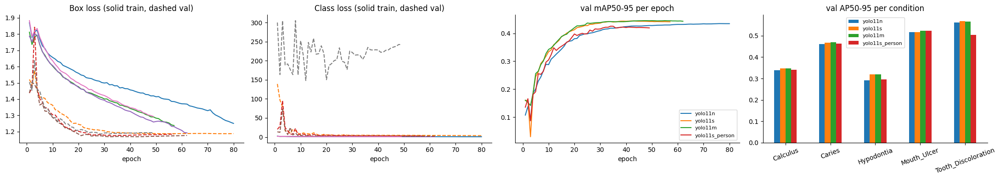

,yolo11n,yolo11s,yolo11m,yolo11s_person
Calculus,0.338,0.347,0.347,0.341
Caries,0.462,0.469,0.471,0.463
Hypodontia,0.293,0.318,0.319,0.295
Mouth_Ulcer,0.518,0.517,0.524,0.524
Tooth_Discoloration,0.563,0.570,0.567,0.505


In [ ]:
rows = []
for name in CFG["sweep"]:
    v, vp, h = evaluate(name, EVAL_DATA, "val", "val"), evaluate(name, EVAL_PERSON, "val", "val_person"), history(name)
    fitness = 0.1 * h["metrics/mAP50(B)"] + 0.9 * h["metrics/mAP50-95(B)"]
    dt = h["time"].diff().fillna(h["time"].iloc[0])
    dt[dt <= 0] = h["time"][dt <= 0]                     # the clock restarts when a run resumes
    rows.append(dict(run=name, model=EXPERIMENTS[name]["model"].removesuffix(".pt"), train_images=train_list_size(name),
                     epochs_run=len(h), best_epoch=int(h.epoch[fitness.idxmax()]), min_per_epoch=dt.median() / 60,
                     params_M=v["params_M"], GFLOPs=v["GFLOPs"], inference_ms=v["inference_ms"],
                     val_P=v["precision"], val_R=v["recall"], val_mAP50=v["mAP50"], val_mAP50_95=v["mAP50_95"],
                     val_person_mAP50_95=vp["mAP50_95"]))
comp = pd.DataFrame(rows).set_index("run")

best_score = comp.val_mAP50_95.max()
tied = comp[comp.val_mAP50_95 >= best_score - CFG["tie_margin"]]
BEST = tied.sort_values(["GFLOPs", "val_mAP50_95"], ascending=[True, False]).index[0]
comp["chosen"] = np.where(comp.index == BEST, "<<", "")
display(comp.round(3))
print(f"chosen: {BEST}  (val mAP50-95 {comp.loc[BEST, 'val_mAP50_95']:.3f}; "
      f"{len(tied)} run(s) within {CFG['tie_margin']} of the best {best_score:.3f})")

pc_val = pd.DataFrame({n: {c: evaluate(n, EVAL_DATA, "val", "val")["per_class"].get(c, {}).get("AP50_95", np.nan)
                           for c in CONDITIONS} for n in CFG["sweep"]})
fig, ax = plt.subplots(1, 4, figsize=(22, 4))
for name in CFG["sweep"]:
    h = history(name)
    ax[0].plot(h.epoch, h["train/box_loss"], label=f"{name} train"); ax[0].plot(h.epoch, h["val/box_loss"], "--", label=f"{name} val")
    ax[1].plot(h.epoch, h["train/cls_loss"], label=name); ax[1].plot(h.epoch, h["val/cls_loss"], "--")
    ax[2].plot(h.epoch, h["metrics/mAP50-95(B)"], label=name)
ax[0].set_title("Box loss (solid train, dashed val)"); ax[1].set_title("Class loss (solid train, dashed val)")
ax[2].set_title("val mAP50-95 per epoch"); ax[2].legend(fontsize=8)
for a in ax[:3]:
    a.set_xlabel("epoch")
pc_val.plot.bar(ax=ax[3], rot=20); ax[3].set_title("val AP50-95 per condition"); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / "train_curves_and_val_per_class.png", bbox_inches="tight"); plt.show()
display(pc_val.round(3))

**Reading the comparison.**
- **Over- or underfitting.** If the val box/class loss rises while the train loss keeps falling, the run is overfitting. Early stopping keeps the best epoch, but a best epoch far before the last one says the model saturated early. If val mAP is still climbing at the last epoch, more epochs would help.
- **Model size.** If `yolo11m` is only marginally better than `yolo11s`, the extra 3× compute is not worth it for a web app. The tie rule picks the smaller model in that case.
- **Ablation (`yolo11s` vs `yolo11s_person`).** If the person-only run matches or beats `yolo11s` on val, the Qwen-labelled images are not helping (they may be adding noisy boxes). If it is clearly worse, the extra images help despite their label noise. Section 6.1 repeats this comparison on person-labelled test images.

## 6. Evaluation on the held-out test set

### 6.1 Box-level metrics

The chosen model is scored twice, as the dataset README recommends:
- **all test images** (`data.yaml`, 3,046 images);
- **person-labelled test images only** (`data_person.yaml`, 2,507 images). This drops the Normal images that Qwen judged healthy.

If the two scores are close, Qwen's Normal labels are fine. If the first is clearly lower, the model is finding things on Qwen's "Normal" images; section 6.3 shows them.

Ultralytics 8.4.211  Python-3.13.14 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.2±0.0 ms, read: 172.7±114.9 MB/s, size: 63.9 KB)
val: Scanning C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\interim\Daniel\yolo_oral_1024\labels\test... 3046 images, 599 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3046/3046 1.7Kit/s 1.8s0.1s
val: New cache created: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\interim\Daniel\yolo_oral_1024\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 96/96 3.7it/s 25.6s0.1ss7
                   all       3046      11692      0.809      0.783       0.84       0.45
Speed: 0.6ms preprocess, 2.0ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-W

,precision,recall,mAP50,mAP50_95
"test, all images",0.809,0.783,0.840,0.450
"test, person-labelled",0.810,0.783,0.841,0.451


all                       person                      
                         P      R   AP50 AP50_95      P      R   AP50 AP50_95
Calculus             0.756  0.580  0.680   0.337  0.756  0.580  0.680   0.337
Caries               0.827  0.784  0.853   0.458  0.830  0.784  0.854   0.459
Hypodontia           0.808  0.794  0.842   0.360  0.809  0.794  0.842   0.360
Mouth_Ulcer          0.889  0.903  0.938   0.515  0.889  0.903  0.938   0.516
Tooth_Discoloration  0.766  0.853  0.890   0.581  0.767  0.853  0.890   0.581

operating confidence threshold (max mean F1 on val): 0.357


**confusion_matrix_normalized.png** (all test images)

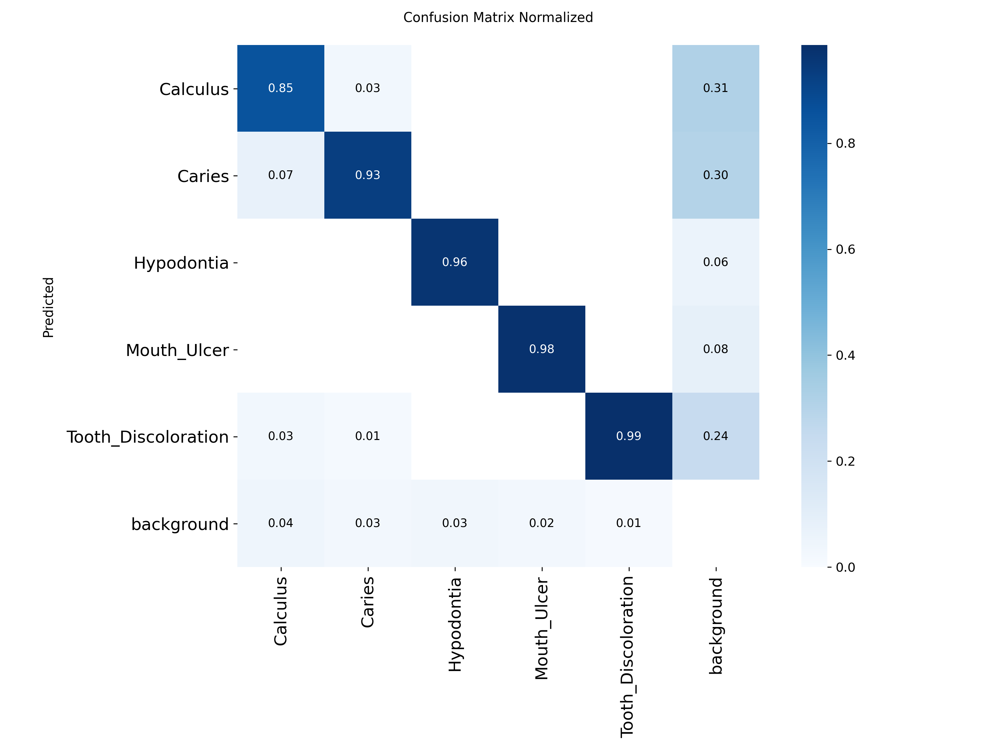

In [ ]:
t_all = evaluate(BEST, EVAL_DATA, "test", "test_all", plots=True)
t_per = evaluate(BEST, EVAL_PERSON, "test", "test_person", plots=True)
CONF = evaluate(BEST, EVAL_DATA, "val", "val")["f1_conf"]   # operating threshold: max mean F1 on VAL

overall = pd.DataFrame({k: {m: r[m] for m in ["precision", "recall", "mAP50", "mAP50_95"]}
                        for k, r in [("test, all images", t_all), ("test, person-labelled", t_per)]}).T
display(overall.round(3))
per_class = pd.concat({k: pd.DataFrame(r["per_class"]).T for k, r in [("all", t_all), ("person", t_per)]}, axis=1)
per_class = per_class.reindex(CONDITIONS)
display(per_class.round(3))
print(f"operating confidence threshold (max mean F1 on val): {CONF:.3f}")

for f in ["confusion_matrix_normalized.png", "PR_curve.png"]:
    src = Path(t_all["save_dir"]) / f
    if src.exists():
        shutil.copy2(src, FIGS / f"test_{f}")
        display(Markdown(f"**{f}** (all test images)"), IPImage(filename=str(src), width=720))

In [ ]:
# The ablation on clean labels: does training on Qwen-labelled images help on person-labelled test images?
# Reported for the report only. Selection was done on val above.
pairs = [(a, b) for a, b in [("yolo11s", "yolo11s_person")] if a in CFG["sweep"] and b in CFG["sweep"]]
abl = {}
for a, b in pairs:
    for n in (a, b):
        r = evaluate(n, EVAL_PERSON, "test", "test_person")
        abl[n] = {"mAP50": r["mAP50"], "mAP50_95": r["mAP50_95"],
                  **{f"AP50_95 {c}": r["per_class"].get(c, {}).get("AP50_95", np.nan) for c in CONDITIONS}}
if abl:
    abl = pd.DataFrame(abl).T
    display(Markdown("**Ablation on person-labelled test images** (`yolo11s` trained on all images vs. person-labelled only)"))
    display(abl.round(3))

Ultralytics 8.4.211  Python-3.13.14 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 378.7±69.9 MB/s, size: 38.4 KB)
val: Scanning C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\data\interim\Daniel\yolo_oral_1024\labels\test.cache... 2507 images, 60 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2507/2507 955.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 79/79 3.5it/s 22.8s0.1ss
                   all       2507      11692      0.799      0.769      0.823      0.438
Speed: 0.6ms preprocess, 2.2ms inference, 0.0ms loss, 0.7ms postprocess per image


**Ablation on person-labelled test images** (`yolo11s` trained on all images vs. person-labelled only)

,mAP50,mAP50_95,AP50_95 Calculus,AP50_95 Caries,AP50_95 Hypodontia,AP50_95 Mouth_Ulcer,AP50_95 Tooth_Discoloration
yolo11s,0.841,0.451,0.337,0.459,0.360,0.516,0.581
yolo11s_person,0.823,0.438,0.325,0.449,0.341,0.497,0.577


### 6.2 Image-level view: what a user of the app would see

The app does not show mAP. It shows boxes above a confidence threshold. Here every test image is run through the chosen model once. An image counts as **flagged** if it gets at least one box at the operating threshold (the confidence where mean F1 peaks on val). That gives:
- **sensitivity**: share of images with a condition that get at least one box;
- **false-alarm rate**: share of Normal images that get a box anyway;
- per condition, **recall** (images that have the condition and get a box of that class) and **precision** (images given a box of that class that really have it).

In the full pipeline, stage 1 has already filtered most healthy mouths, so the false-alarm rate here is a worst case.

predict test: 100%|██████████| 96/96 [00:14<00:00,  6.55batch/s]


**Screening view at conf >= 0.357**

,issue_images,normal_images,sensitivity,false_alarm_rate
all test images,2447.0,599.0,0.986,0.025
person-labelled,2447.0,60.0,0.986,0.083


**Per condition, image level (test)**

,images_with,recall,precision,F1
Calculus,415.0,0.759,0.868,0.810
Caries,811.0,0.920,0.934,0.927
Hypodontia,397.0,0.940,0.930,0.935
Mouth_Ulcer,568.0,0.991,0.996,0.994
Tooth_Discoloration,885.0,0.927,0.842,0.882


**False alarms on Normal test images, by source** (who judged them Normal)

,,images,false_alarm_rate
dataset,label_by,,
dentalai,person (caries) + qwen (other conditions),92,0.076
external_clean,qwen,6,0.167
kaggle_oral,person,60,0.083
mendeley_noncaries,qwen,435,0.000
zenodo,person (caries) + qwen (other conditions),6,0.333


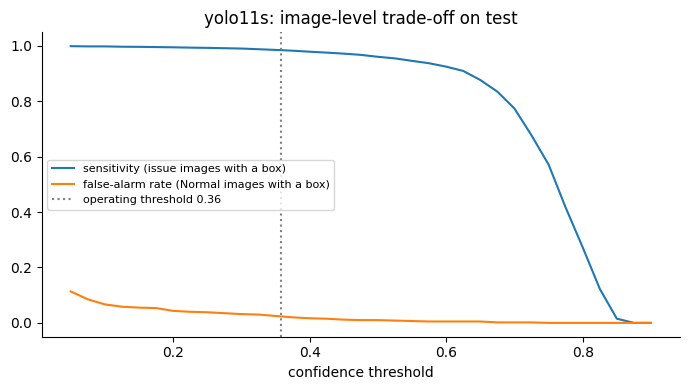

In [ ]:
def predict_images(name, images, tag):
    # Every detection with conf >= pred_conf, one row per box: image, cls, conf, x1 y1 x2 y2 (0-1). Cached per run.
    out = run_dir(name) / f"pred_{tag}.csv"
    if out.exists() and out.stat().st_mtime > final_ckpt(name).stat().st_mtime:
        return pd.read_csv(out)
    model, recs, bs = YOLO(str(final_ckpt(name))), [], CFG["batch"]
    key = lambda p: os.path.normcase(os.path.abspath(p))
    # Fed in chunks: given a Python list, Ultralytics runs the WHOLE list as one batch (3,000 images -> out of memory).
    # It also sorts the list, so results are matched back to images by path, not by position.
    with working_dir(PRETRAINED):
        for i in tqdm(range(0, len(images), bs), desc=f"predict {tag}", unit="batch"):
            chunk = {key(TRAIN_DATA / p): p for p in images[i:i + bs]}
            res = model.predict(list(chunk), imgsz=CFG["imgsz"], conf=CFG["pred_conf"], iou=0.7, device=DEVICE,
                                verbose=False)
            for r in res:
                img = chunk[key(r.path)]
                for c, p, xy in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxyn.tolist()):
                    recs.append((img, int(c), p, *xy))
    pred = pd.DataFrame(recs, columns=["image", "cls", "conf", "x1", "y1", "x2", "y2"])
    pred.to_csv(out, index=False)
    return pred


def flags(pred, images, conf):
    # image x condition: did the model draw a box of that class at this confidence?
    p = pred[pred.conf >= conf]
    hit = (pd.crosstab(p.image, p.cls) > 0).reindex(index=images, columns=range(NC), fill_value=False)
    hit.columns = CONDITIONS
    hit["any"] = hit.any(axis=1)
    return hit


def screening(images, pred, conf):
    g, h = GT_IMG.loc[images], flags(pred, images, conf)
    issue, normal = g["any"], ~g["any"]
    return dict(issue_images=int(issue.sum()), normal_images=int(normal.sum()),
                sensitivity=(h["any"] & issue).sum() / max(issue.sum(), 1),
                false_alarm_rate=(h["any"] & normal).sum() / max(normal.sum(), 1))


test_imgs = df.image[df.split == "test"].tolist()
PRED = predict_images(BEST, test_imgs, "test")
meta = df.set_index("image")

scr = pd.DataFrame({k: screening(imgs, PRED, CONF) for k, imgs in [
    ("all test images", test_imgs), ("person-labelled", [i for i in test_imgs if meta.person[i]])]}).T
display(Markdown(f"**Screening view at conf >= {CONF:.3f}**")); display(scr.round(3))

g, h = GT_IMG.loc[test_imgs], flags(PRED, test_imgs, CONF)
img_pc = pd.DataFrame({c: dict(images_with=int(g[c].sum()), recall=(g[c] & h[c]).sum() / max(g[c].sum(), 1),
                               precision=(g[c] & h[c]).sum() / max(h[c].sum(), 1)) for c in CONDITIONS}).T
img_pc["F1"] = 2 * img_pc.precision * img_pc.recall / (img_pc.precision + img_pc.recall).replace(0, np.nan)
display(Markdown("**Per condition, image level (test)**")); display(img_pc.round(3))

normal_imgs = [i for i in test_imgs if not GT_IMG.loc[i, "any"]]
fa = (meta.loc[normal_imgs, ["dataset", "label_by"]].assign(false_alarm=h.loc[normal_imgs, "any"].values)
      .groupby(["dataset", "label_by"]).false_alarm.agg(images="size", false_alarm_rate="mean"))
display(Markdown("**False alarms on Normal test images, by source** (who judged them Normal)")); display(fa.round(3))

ths = np.linspace(0.05, 0.9, 35)
curve = pd.DataFrame([screening(test_imgs, PRED, t) for t in ths], index=ths)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ths, curve.sensitivity, label="sensitivity (issue images with a box)")
ax.plot(ths, curve.false_alarm_rate, label="false-alarm rate (Normal images with a box)")
ax.axvline(CONF, color="grey", ls=":", label=f"operating threshold {CONF:.2f}")
ax.set_xlabel("confidence threshold"); ax.set_title(f"{BEST}: image-level trade-off on test"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / "test_image_level_tradeoff.png", bbox_inches="tight"); plt.show()

### 6.3 Normal test images where the model fires

These are the Normal test images with the most confident detections. Look at each one: is it a real false alarm (shadow, restoration, lip texture), or did the label miss something? A label that missed something is most likely on images whose `label_by` is `qwen`. If several images in this gallery show real findings, the gap between the two test scores in 6.1 is partly a labelling problem, not a model problem.

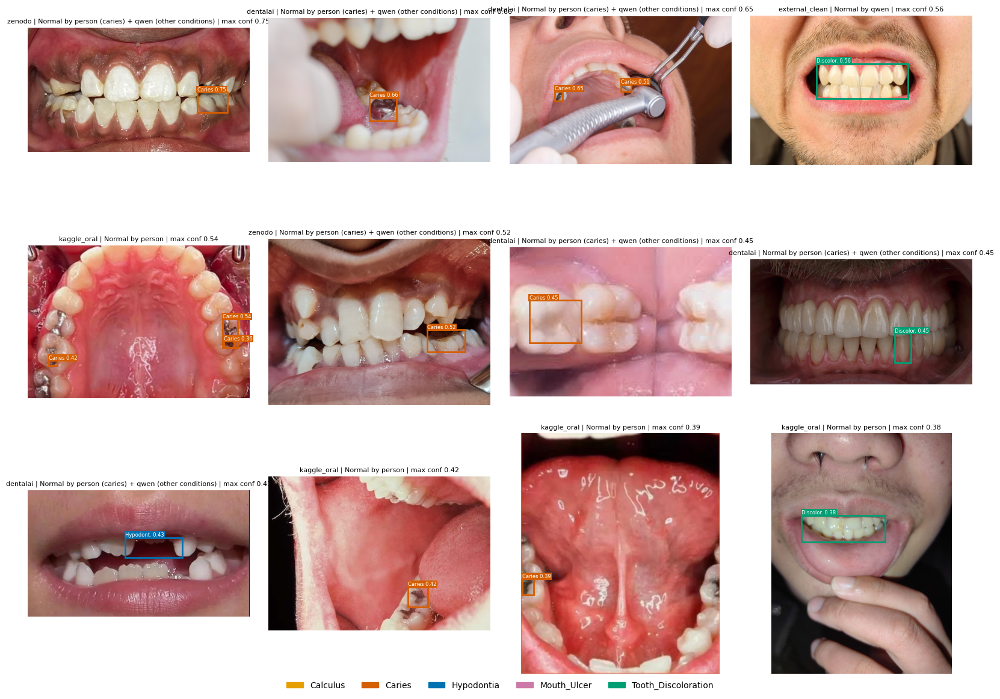

In [ ]:
top = PRED[PRED.image.isin(normal_imgs)].groupby("image").conf.max().sort_values(ascending=False)
top = top[top >= CONF].head(12)
if len(top):
    n_rows = int(np.ceil(len(top) / 4))
    fig, axes = plt.subplots(n_rows, 4, figsize=(16, 4 * n_rows), squeeze=False)
    for ax, img in zip(axes.flat, top.index):
        draw(ax, img, root=TRAIN_DATA, gt=False, preds=PRED[PRED.image == img], conf=CONF,
             title=f"{meta.dataset[img]} | Normal by {meta.label_by[img]} | max conf {top[img]:.2f}")
    for ax in axes.flat[len(top):]:
        ax.set_axis_off()
    class_legend(fig)
    plt.tight_layout(); plt.savefig(FIGS / "test_normal_false_alarms.png", bbox_inches="tight", dpi=80); plt.show()
else:
    print("No Normal test image gets a box at the operating threshold.")

### 6.4 Example predictions

Three person-labelled test images per condition. Ground-truth boxes are **dashed**; the model's boxes at the operating threshold are **solid** and labelled with their confidence.

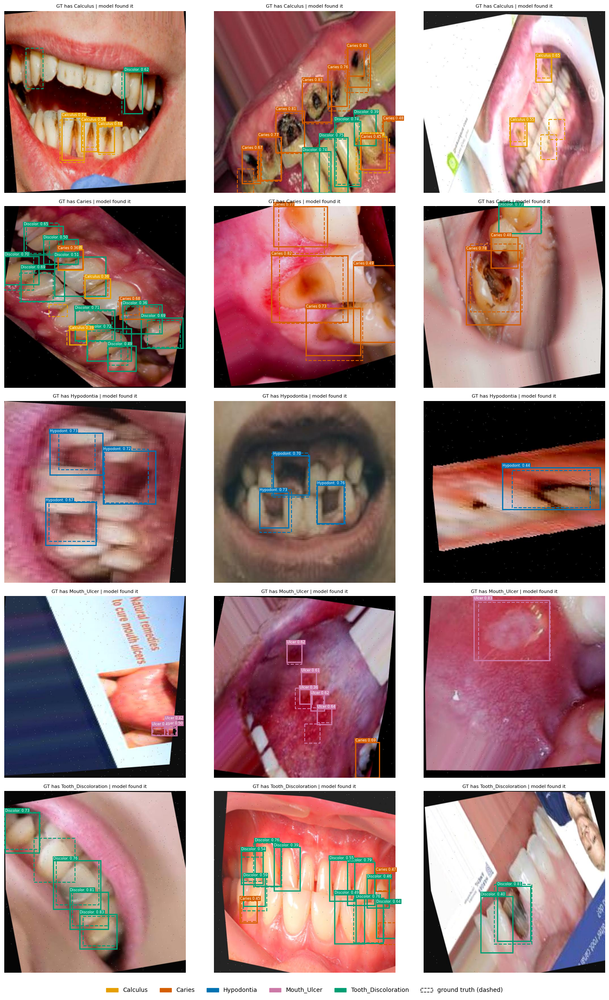

In [ ]:
rng = np.random.default_rng(CFG["seed"])
fig, axes = plt.subplots(NC, 3, figsize=(15, 4.6 * NC))
for c, row in enumerate(axes):
    pool = [i for i in test_imgs if GT_IMG.loc[i, CONDITIONS[c]] and meta.person[i]]
    for ax, img in zip(row, rng.choice(pool, min(3, len(pool)), replace=False)):
        hit = flags(PRED, [img], CONF).loc[img, CONDITIONS[c]]
        draw(ax, img, root=TRAIN_DATA, preds=PRED[PRED.image == img], conf=CONF,
             title=f"GT has {CONDITIONS[c]} | model {'found it' if hit else 'MISSED it'}")
class_legend(fig, [Patch(fc="none", ec="k", ls="--", label="ground truth (dashed)")])
plt.tight_layout(); plt.savefig(FIGS / "test_examples.png", bbox_inches="tight", dpi=80); plt.show()

## 7. Save the model and results

- `weights/Daniel/best.pt`: the chosen checkpoint (gitignored; share it separately). `best.json` next to it records which run it is, the classes, the image size and the operating confidence threshold. The app needs all of these.
- `results/Daniel/`: `test_metrics.json`, `comparison_val.csv`, `test_per_class.csv`, `test_screening.csv`, `test_image_level_per_condition.csv`, the per-epoch history of every run in `history/`, and the figures in `figures/`.
- One row per run is upserted into the team log `models/yolo_caries/results/experiments.csv` (val metrics; test metrics are in the notes of the chosen run). Quick-mode runs are never logged.

In [ ]:
shutil.copy2(final_ckpt(BEST), WEIGHTS / "best.pt")
deploy = dict(run=BEST, weights=rel(WEIGHTS / "best.pt"), classes=CONDITIONS, imgsz=CFG["imgsz"], conf=round(CONF, 3),
              iou=0.7, trained=datetime.date.fromtimestamp(final_ckpt(BEST).stat().st_mtime).isoformat(),
              dataset=rel(DATA_DIR), ultralytics=ultralytics.__version__)
to_json(deploy, WEIGHTS / "best.json")

comp.to_csv(RESULTS / "comparison_val.csv")
per_class.to_csv(RESULTS / "test_per_class.csv")
scr.to_csv(RESULTS / "test_screening.csv")
img_pc.to_csv(RESULTS / "test_image_level_per_condition.csv")
for name in CFG["sweep"]:
    shutil.copy2(run_dir(name) / "results.csv", HISTORY / f"{name}.csv")
args_best = yaml.safe_load(open(run_dir(BEST) / "args.yaml"))
to_json(dict(chosen=BEST, selection="highest val mAP50-95 (data.yaml); ties within "
             f"{CFG['tie_margin']} -> fewest GFLOPs", deploy=deploy, cfg=CFG, train_args=args_best,
             val=comp.drop(columns="chosen").to_dict(orient="index"),
             test_all={k: v for k, v in t_all.items() if k != "save_dir"},
             test_person={k: v for k, v in t_per.items() if k != "save_dir"},
             image_level=dict(conf=CONF, screening=scr.to_dict(orient="index"), per_condition=img_pc.to_dict(orient="index"),
                              false_alarm_by_source=fa.reset_index().to_dict(orient="records")),
             ablation_test_person=abl.to_dict(orient="index") if isinstance(abl, pd.DataFrame) else None),
        RESULTS / "test_metrics.json")

if not QUICK:
    log_cols = pd.read_csv(EXPERIMENT_LOG, nrows=0).columns.tolist()
    log = pd.read_csv(EXPERIMENT_LOG)
    data_version = f"oral_dataset {datetime.date.fromtimestamp((DATA_DIR / 'labels.csv').stat().st_mtime)}"
    new = []
    for name in CFG["sweep"]:
        a, r = yaml.safe_load(open(run_dir(name) / "args.yaml")), comp.loc[name]
        note = f"val=data.yaml; trained on {EXPERIMENTS[name]['data']}; best epoch {r.best_epoch}/{r.epochs_run}"
        if name == BEST:
            note += (f"; CHOSEN; test mAP50-95 all={t_all['mAP50_95']:.3f} person={t_per['mAP50_95']:.3f}; "
                     f"conf={CONF:.3f}")
        new.append(dict(run_id=f"Daniel_{name}_{a['imgsz']}", date=datetime.date.today().isoformat(), member="Daniel",
                        model=r.model, data_version=data_version, imgsz=a["imgsz"], epochs=r.epochs_run, batch=a["batch"],
                        lr0=a["lr0"], mAP50=round(r.val_mAP50, 4), mAP50_95=round(r.val_mAP50_95, 4),
                        precision=round(r.val_P, 4), recall=round(r.val_R, 4), weights_path=rel(final_ckpt(name)),
                        notes=note))
    new = pd.DataFrame(new)[log_cols]
    log = pd.concat([log[~log.run_id.isin(new.run_id)], new], ignore_index=True)
    log.to_csv(EXPERIMENT_LOG, index=False)
    print(f"logged {len(new)} run(s) to {rel(EXPERIMENT_LOG)}")
print("saved:", rel(WEIGHTS / "best.pt"), "|", rel(RESULTS))

logged 4 run(s) to models/yolo_caries/results/experiments.csv
saved: models/yolo_caries/weights/Daniel/best.pt | models/yolo_caries/results/Daniel


## 8. Results at a glance

In [ ]:
r = comp.loc[BEST]
abl_line = ""
if isinstance(abl, pd.DataFrame) and len(abl) == 2:
    d = abl.loc["yolo11s_person", "mAP50_95"] - abl.loc["yolo11s", "mAP50_95"]
    abl_line = (f"- **Ablation:** training only on person-labelled images changes person-labelled test mAP50-95 by "
                f"**{d:+.3f}** ({abl.loc['yolo11s', 'mAP50_95']:.3f} -> {abl.loc['yolo11s_person', 'mAP50_95']:.3f}): "
                + ("the Qwen-labelled images help." if d < -CFG["tie_margin"] else
                   "the Qwen-labelled images hurt." if d > CFG["tie_margin"] else "no clear difference.") + "\n")
worst, best_c = per_class[("person", "AP50_95")].idxmin(), per_class[("person", "AP50_95")].idxmax()
display(Markdown(f"""
{"> **QUICK mode**: 2 epochs on 3% of train. These numbers only show that the notebook runs." if QUICK else ""}

- **Chosen model:** `{BEST}` ({r.params_M:.1f} M params, {r.GFLOPs:.1f} GFLOPs, {r.inference_ms:.1f} ms/image on this GPU),
  best epoch {r.best_epoch} of {r.epochs_run}. Val mAP50-95 **{r.val_mAP50_95:.3f}**, mAP50 {r.val_mAP50:.3f}.
- **Test, all images:** mAP50-95 **{t_all['mAP50_95']:.3f}**, mAP50 {t_all['mAP50']:.3f}, P {t_all['precision']:.3f}, R {t_all['recall']:.3f}.
- **Test, person-labelled images:** mAP50-95 **{t_per['mAP50_95']:.3f}**, mAP50 {t_per['mAP50']:.3f}.
  Gap to "all images": {t_per['mAP50_95'] - t_all['mAP50_95']:+.3f}.
- **Per condition (person-labelled test, AP50-95):** best {best_c} ({per_class.loc[best_c, ('person', 'AP50_95')]:.3f}),
  weakest {worst} ({per_class.loc[worst, ('person', 'AP50_95')]:.3f}).
- **Image level at conf {CONF:.2f}:** {scr.loc['all test images', 'sensitivity']:.1%} of test images with a condition get a box;
  {scr.loc['all test images', 'false_alarm_rate']:.1%} of Normal test images get a false alarm.
{abl_line}"""))




- **Chosen model:** `yolo11s` (9.4 M params, 21.7 GFLOPs, 2.0 ms/image on this GPU),
  best epoch 42 of 57. Val mAP50-95 **0.444**, mAP50 0.821.
- **Test, all images:** mAP50-95 **0.450**, mAP50 0.840, P 0.809, R 0.783.
- **Test, person-labelled images:** mAP50-95 **0.451**, mAP50 0.841.
  Gap to "all images": +0.000.
- **Per condition (person-labelled test, AP50-95):** best Tooth_Discoloration (0.581),
  weakest Calculus (0.337).
- **Image level at conf 0.36:** 98.6% of test images with a condition get a box;
  2.5% of Normal test images get a false alarm.
- **Ablation:** training only on person-labelled images changes person-labelled test mAP50-95 by **-0.013** (0.451 -> 0.438): the Qwen-labelled images help.


## 9. Limitations and responsible-AI notes (for the report)

- **Not a diagnosis.** The detector marks regions that *look like* one of five conditions in a phone photo. It cannot see below the gum line or between teeth, and it is never a substitute for an examination or an X-ray. Every result in the app must recommend seeing a dentist.
- **Test images are mostly one source.** Every test image with a condition is a 640×640 `roboflow_oral` export. The test score says how the model does on photos like those. Clinical photos (dentalai, zenodo) and everyday phone photos may score lower. The per-source false-alarm table in 6.2 is the only out-of-source evidence here.
- **Augmented copies.** Many `roboflow_oral` images, in test as well as train, are Roboflow augmentations: rotated, sheared, cropped or colour-shifted copies of a photo. The dataset keeps all copies of one photo in the same split, so this is not leakage. But test photos look less like real phone photos than the numbers suggest, and copies of one photo count several times.
- **Label noise.** About 7,250 training images (28%) were labelled at least partly by Qwen, a vision-language model. The `yolo11s_person` ablation measures whether they help. Some Normal val/test images were also judged by Qwen and may hide small findings (6.3).
- **Five conditions only.** Gum disease, fractures, oral cancer and many other conditions are not classes. No box does not mean a healthy mouth.
- **Box conventions differ by source.** Some sources box each tooth, others one region. This lowers mAP at strict IoU (mAP50-95) more than at mAP50, and does not necessarily mean the finding was missed. The image-level view in 6.2 is closer to what matters to a user.
- **Threshold.** The operating confidence is chosen on val for maximum mean F1. A screening app may prefer a lower threshold (more sensitivity, more false alarms). The trade-off curve in 6.2 shows the cost of each choice.
- **Privacy.** Mouth photos are health data. The app should process them without storing them, or only with explicit consent.